# Super cool experiment

In [2]:
import spatialdata_io
import spatialdata as sd
import troutpy
import scanpy as sc
from spatialdata import SpatialData
import matplotlib.pyplot as plt

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)


In [ ]:


path = "/media/sergio/Discovair_final/PD_AnaMunoz/Xenium_PD_ana/20231102__180133__20231102_AnaMunoz_run1/output-XETG00045__0010666__2306C__20231102__180214"
sdata = spatialdata_io.xenium(path)

/home/sergio/.local/lib/python3.10/site-packages/dask/dataframe/__init__.py:31: FutureWarning: The legacy Dask DataFrame implementation is deprecated and will be removed in a future version. Set the configuration option `dataframe.query-planning` to `True` or None to enable the new Dask Dataframe implementation and silence this warning.
  warnings.warn(
/home/sergio/.local/lib/python3.10/site-packages/numba/core/decorators.py:246: RuntimeWarning: nopython is set for njit and is ignored
  warnings.warn('nopython is set for njit and is ignored', RuntimeWarning)
/home/sergio/.local/lib/python3.10/site-packages/anndata/utils.py:429: FutureWarning: Importing read_text from `anndata` is deprecated. Import anndata.io.read_text instead.
  warnings.warn(msg, FutureWarning)
/tmp/ipykernel_1619699/4265107069.py:4: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = spatial

INFO     reading                                                                                                   
         /media/sergio/Discovair_final/PD_AnaMunoz/Xenium_PD_ana/20231102__180133__20231102_AnaMunoz_run1/output-XE
         TG00045__0010666__2306C__20231102__180214/cell_feature_matrix.h5                                          


In [2]:
outpath = "/media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C.zarr"
sdata.write(outpath)

INFO     The Zarr backing store has been changed from None the new file path:                                      
         /media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C.zarr                                      


## Import packages

In [ ]:
transcripts=sdata['transcripts'].compute()
transcripts.reset_index(drop=True,inplace=True)
sdata['transcripts']=sd.models.PointsModel.parse(transcripts)

In [15]:
troutpy.pp.define_extracellular(sdata,layer='transcripts',method='nuclei')

### Process cell expressions

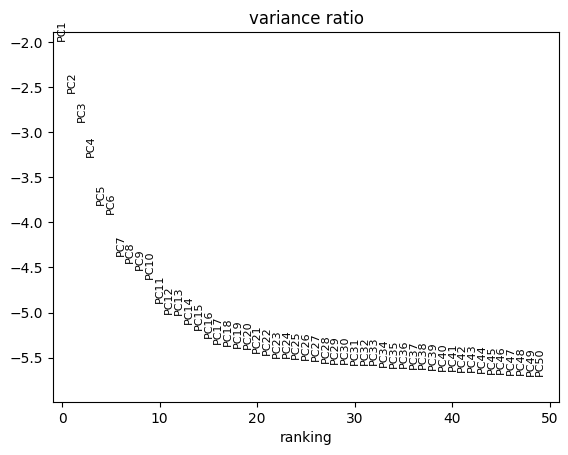

In [ ]:
adata = sdata["table"]
print(adata.shape)
adata.raw = adata.copy()
sc.pp.filter_cells(adata, min_genes=10)
sc.pp.filter_genes(adata, min_cells=3)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
sc.pp.neighbors(adata)
sc.tl.umap(adata)
print(adata.shape)
sc.tl.leiden(adata, key_added="leiden")

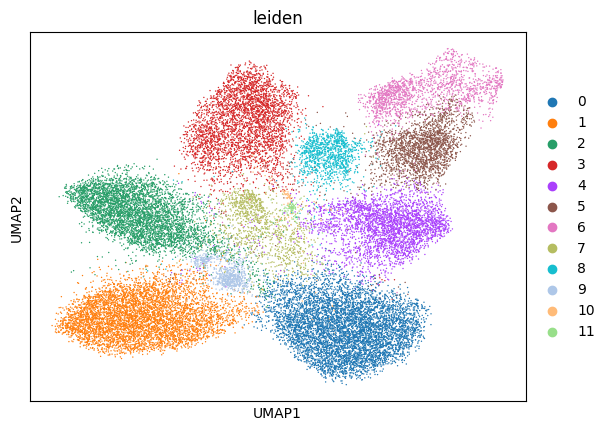

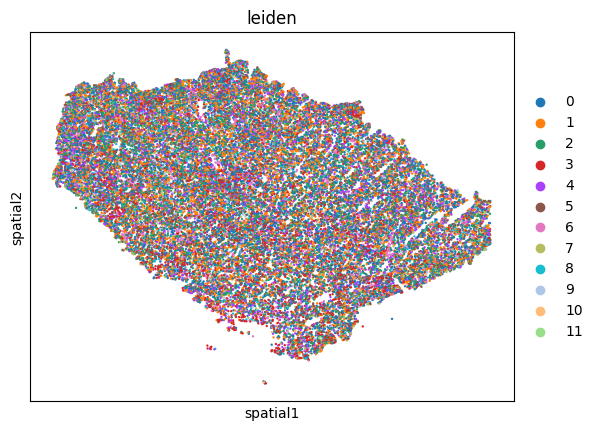

In [26]:
sc.pl.umap(adata,color='leiden')
sc.pl.spatial(adata,color='leiden',spot_size=50)

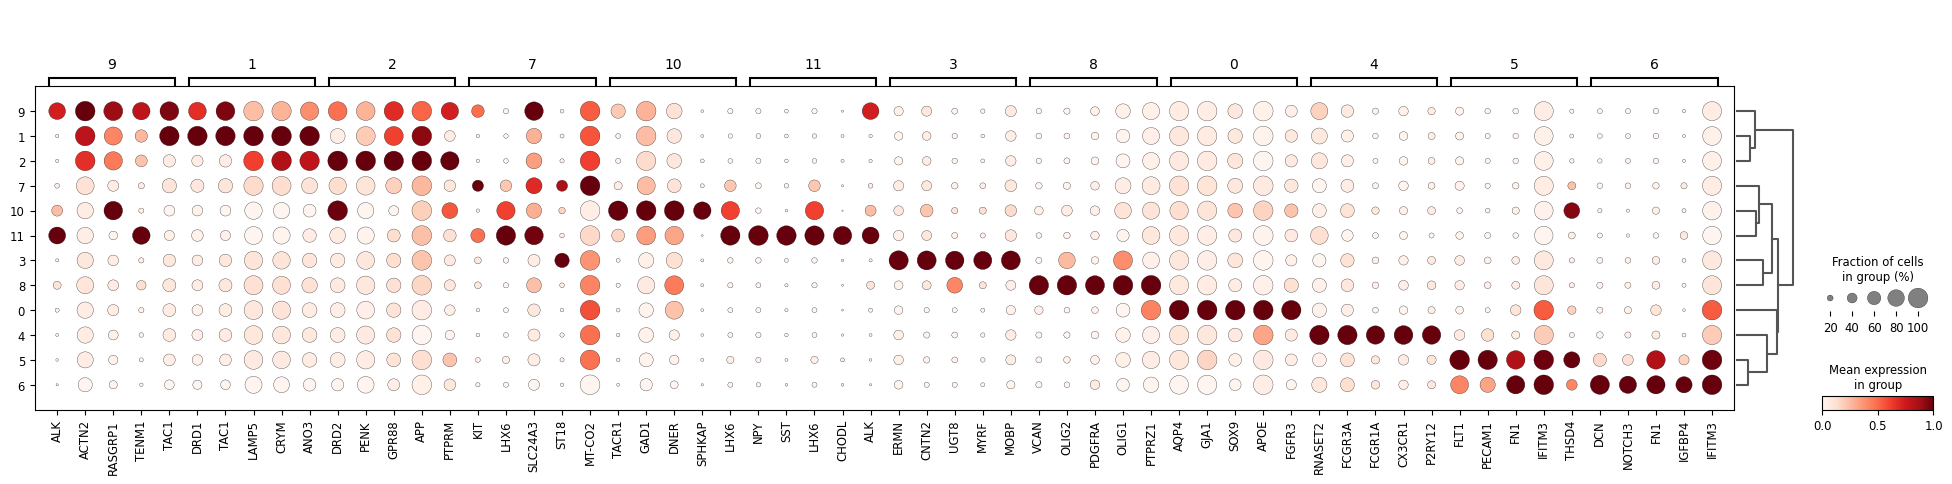

In [27]:
sc.tl.rank_genes_groups(adata, groupby="leiden", method="wilcoxon")
sc.pl.rank_genes_groups_dotplot(adata, groupby="leiden", standard_scale="var", n_genes=5)

## Quantify exRNa

In [34]:
import numpy as np
gen=np.unique(sdata['transcripts']['feature_name'].compute())

In [67]:
control_codewords = [g for g in gen if 'NegCon' in g ]

troutpy.tl.quantify_overexpression(
    sdata,
    layer="transcripts",
    codeword_column="feature_name",
    control_codewords=list(control_codewords),
    gene_id_column="feature_name",
    percentile_threshold=99.99)

(42897133, 2)
Added 'xrna_metadata' table with 541 unique genes to the SpatialData object.


In [69]:
troutpy.tl.extracellular_enrichment(sdata)

In [70]:
troutpy.tl.spatial_variability(sdata, gene_id_key="feature_name", coords_keys=["x", "y"], n_neighbors=10, binsize=20)

Extracting gene counts: 100%|██████████| 541/541 [00:01<00:00, 284.14it/s]


In [71]:
xenium_path_cropped = "/media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C_processed.zarr"
sdata.write(xenium_path_cropped, overwrite=True)

INFO     The Zarr backing store has been changed from                                                              
         /media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C.zarr the new file path:                   
         /media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C_processed.zarr                            


## Signature analysis

In [3]:
xenium_path_cropped = "/media/sergio/Discovair_final/PD_AnaMunoz/sdata_formatted/2306C_processed.zarr"
sdata=sd.read_zarr(xenium_path_cropped)

In [16]:
troutpy.pp.aggregate_extracellular_transcripts(sdata,square_size = 100)

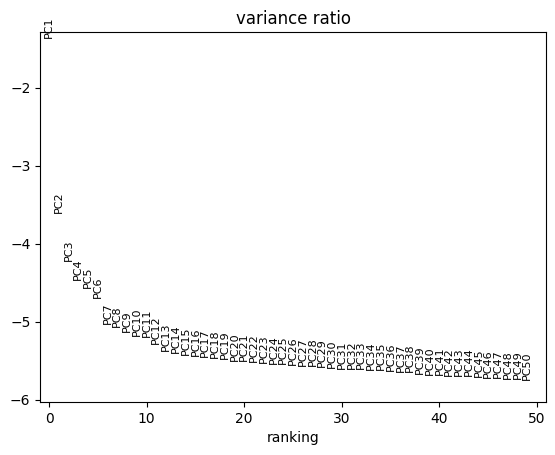

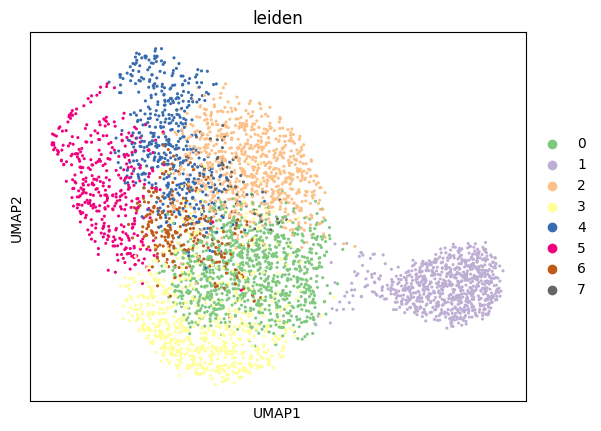

In [17]:
adata=sdata.tables['segmentation_free_table']
adata.raw = adata
sc.pp.filter_cells(adata, min_genes=18)
sc.pp.filter_cells(adata, min_counts=130)
sc.pp.filter_genes(adata, min_cells=20)
adata.layers["raw"] = adata.X.copy()
sc.pp.normalize_total(adata)
# Logarithmize the data
sc.pp.log1p(adata)
#pca
sc.tl.pca(adata)
sc.pl.pca_variance_ratio(adata, n_pcs=50, log=True)
# neighbors
sc.pp.neighbors(adata)
sc.tl.umap(adata)
sc.tl.leiden(adata, key_added="leiden",resolution=0.7)
sc.pl.umap(adata,color='leiden',palette='Accent',s=20)

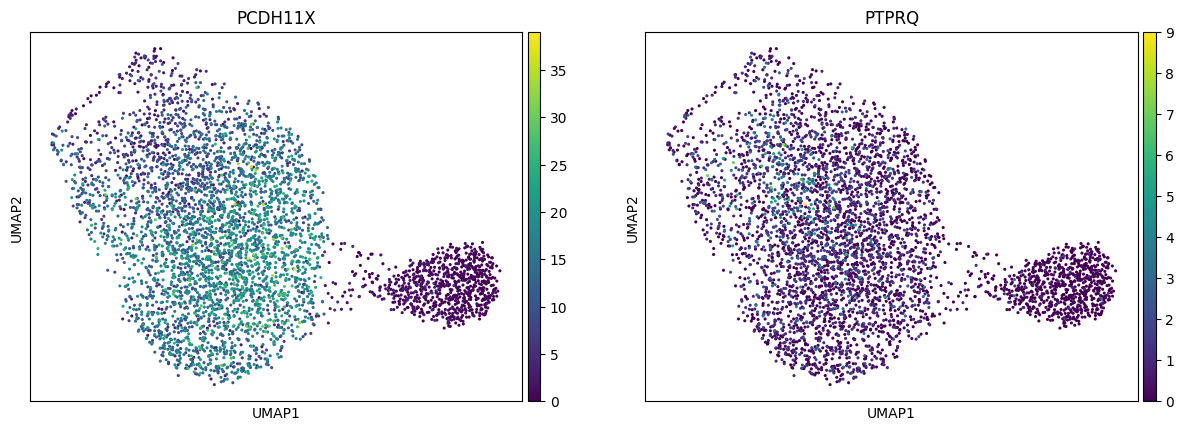

In [18]:
sc.pl.umap(adata,color=['PCDH11X','PTPRQ'],palette='Set1',s=20)

[<Axes: title={'center': 'leiden'}, xlabel='spatial1', ylabel='spatial2'>]

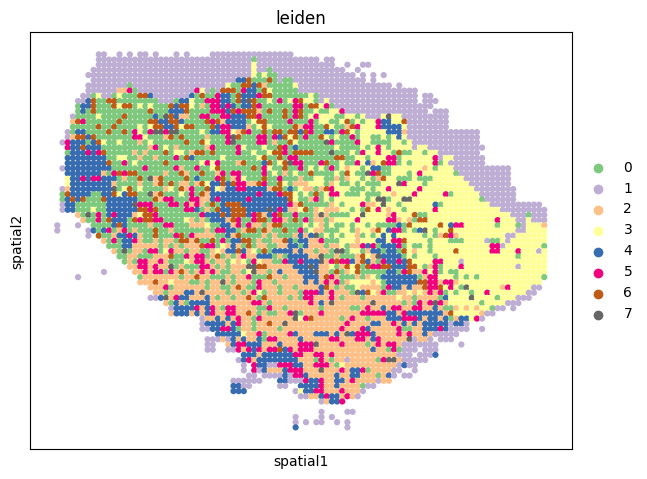

In [21]:
fig,ax=plt.subplots(figsize=(7,7))
sc.pl.spatial(adata, color="leiden", spot_size=120,show=False,ax=ax,marker='s')
#sc.pl.spatial(sdata['table'], color="leiden", spot_size=40,show=False,ax=ax,marker='*',outline_width=(0.8, 0.05),outline_color='black')

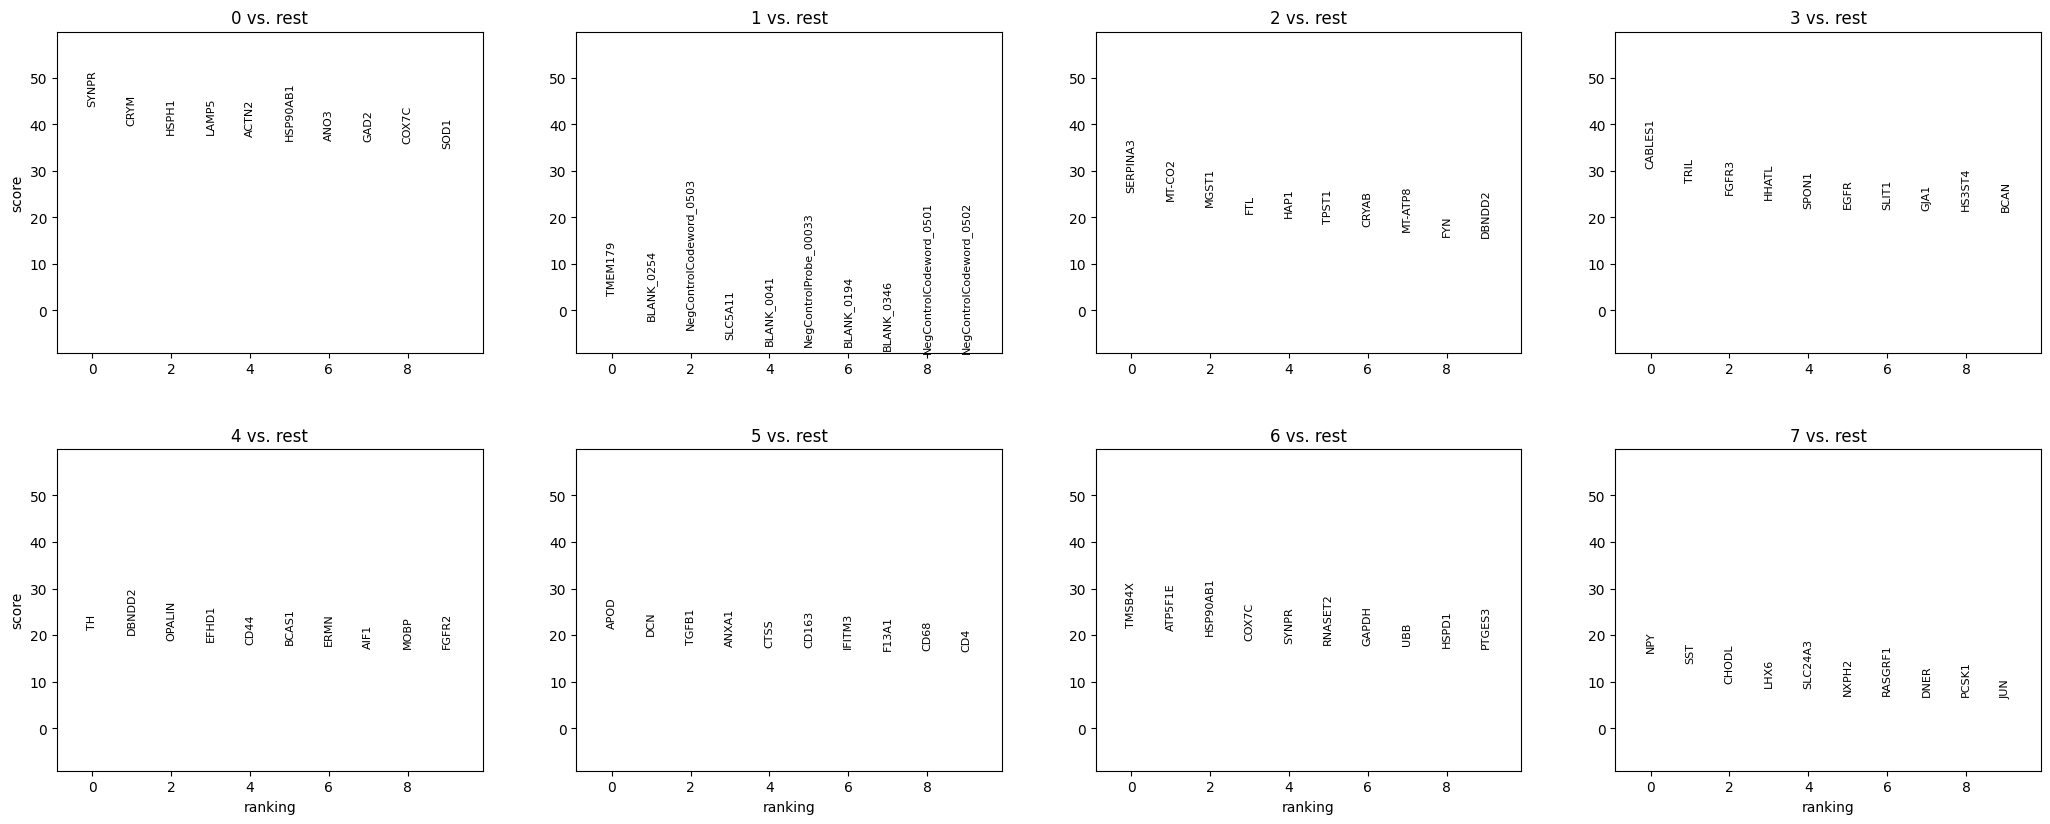

In [24]:
sc.tl.dendrogram(adata,groupby='leiden')
sc.tl.rank_genes_groups(adata,groupby='leiden')
sc.pl.rank_genes_groups(adata,groupby='leiden',n_genes=10)

In [25]:
troutpy.tl.latent_factor(sdata,method='NMF',layer_key='segmentation_free_table', n_components=10)

In [26]:
troutpy.tl.apply_exrna_factors_to_cells(sdata, extracellular_key = "segmentation_free_table", cellular_key='table')

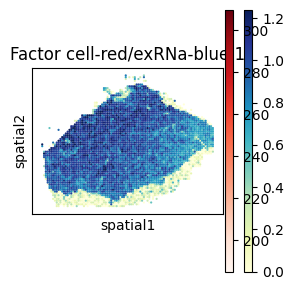

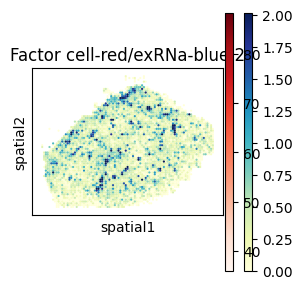

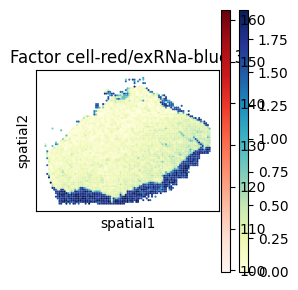

In [36]:
troutpy.pl.paired_nmf_factors(sdata,layer='segmentation_free_table',spot_size_exrna=120,spot_size_cells=0, figsize=(3, 3), n_factors=3)

In [ ]:
sdata['xrna_metadata'].var.sort_values(by='extracellular_proportion',ascending=False).head(10)

,count,control_probe,logfoldratio_over_noise,extracellular_proportion,intracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh
ARL17B,38983,False,0.812411,0.628505,0.371495,2.268003,0.071089,0.0,0.000001,0.0
ANKRD18A,41441,False,0.873556,0.582081,0.417919,2.073516,0.080962,0.0,0.000001,0.0
OVCH1,10699,False,-0.480564,0.558090,0.441910,1.975608,0.027539,0.0,0.000001,0.0
CNDP1,19117,False,0.099864,0.534812,0.465188,1.881669,0.095261,0.0,0.000001,0.0
CNTNAP3B,88888,False,1.636663,0.531793,0.468207,1.869539,0.181020,0.0,0.000001,0.0
...,...,...,...,...,...,...,...,...,...,...
UNC13C,17374,False,0.004260,0.048233,0.951767,-1.240081,0.093678,0.0,0.000001,0.0
MT-ATP8,144760,False,2.124363,0.043465,0.956535,-1.349165,0.446730,0.0,0.000001,0.0
MT-CO2,6091055,False,5.863862,0.034627,0.965373,-1.585685,0.859567,0.0,0.000001,0.0
BLANK_0066,3124,False,-1.711600,0.016965,0.983035,-2.317271,0.078219,0.0,0.000001,0.0


In [43]:
sdata['xrna_metadata'].var.sort_values(by='extracellular_proportion',ascending=False).tail(10)

,count,control_probe,logfoldratio_over_noise,extracellular_proportion,intracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh
IDO1,4746,False,-1.293412,0.065950,0.934050,-0.908433,0.018014,0.0,0.000001,0.0
SNCG,6320,False,-1.006995,0.056013,0.943987,-1.082339,0.047081,0.0,0.000001,0.0
KLRB1,7943,False,-0.778423,0.054388,0.945612,-1.113503,0.081308,0.0,0.000001,0.0
NegControlProbe_00014,2944,True,-1.770945,0.049932,0.950068,-1.203675,0.016189,0.0,0.000001,0.0
POSTN,6785,False,-0.936000,0.048342,0.951658,-1.237711,0.028520,0.0,0.000001,0.0
UNC13C,17374,False,0.004260,0.048233,0.951767,-1.240081,0.093678,0.0,0.000001,0.0
MT-ATP8,144760,False,2.124363,0.043465,0.956535,-1.349165,0.446730,0.0,0.000001,0.0
MT-CO2,6091055,False,5.863862,0.034627,0.965373,-1.585685,0.859567,0.0,0.000001,0.0
BLANK_0066,3124,False,-1.711600,0.016965,0.983035,-2.317271,0.078219,0.0,0.000001,0.0
NegControlProbe_00022,17384,True,0.004836,0.011908,0.988092,-2.676412,0.061196,0.0,0.000001,0.0


In [58]:
sdata['xrna_metadata'].var.sort_values(by='moran_I',ascending=False).head(30)

,count,control_probe,logfoldratio_over_noise,extracellular_proportion,intracellular_proportion,logfoldratio_extracellular,moran_I,moran_pval_norm,moran_var_norm,moran_pval_norm_fdr_bh
MT-CO2,6091055,False,5.863862,0.034627,0.965373,-1.585685,0.859567,0.0,0.000001,0.0
FTL,1504636,False,4.465592,0.095011,0.904989,-0.511734,0.780255,0.0,0.000001,0.0
TMSB4X,1760030,False,4.622372,0.105881,0.894119,-0.391332,0.746512,0.0,0.000001,0.0
CALM2,2147536,False,4.821362,0.123448,0.876552,-0.217985,0.744189,0.0,0.000001,0.0
GAPDH,2931344,False,5.132502,0.110625,0.889375,-0.342181,0.740041,0.0,0.000001,0.0
ATP5F1E,707342,False,3.710800,0.076139,0.923861,-0.753812,0.692493,0.0,0.000001,0.0
UBC,2468782,False,4.960766,0.148291,0.851709,-0.005870,0.686943,0.0,0.000001,0.0
UBB,1347919,False,4.355603,0.140624,0.859376,-0.067920,0.680621,0.0,0.000001,0.0
HSP90AB1,897292,False,3.948667,0.136467,0.863533,-0.102751,0.654743,0.0,0.000001,0.0
COX7C,445762,False,3.249071,0.100134,0.899866,-0.453539,0.636307,0.0,0.000001,0.0


[<Axes: title={'center': 'NNAT'}, xlabel='spatial1', ylabel='spatial2'>]

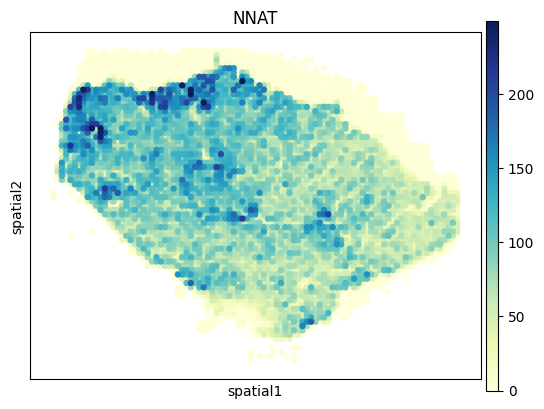

In [61]:
gene='NNAT'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

[<Axes: title={'center': 'MT-CO2'}, xlabel='spatial1', ylabel='spatial2'>]

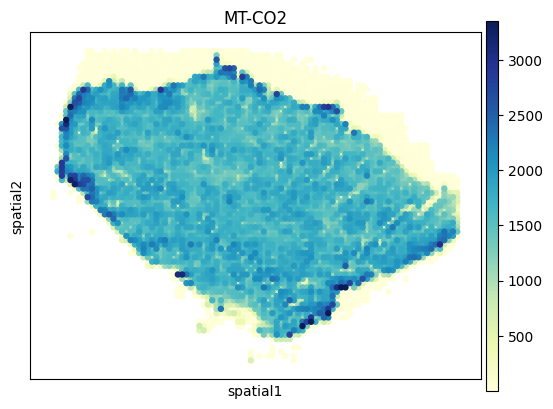

In [52]:
gene='MT-CO2'
sc.pl.spatial(sdata['segmentation_free_table'],color=gene,cmap='YlGnBu',show=False,spot_size=150,vmax='p99.9')

In [ ]:
sdata['xrna_metadata'].var.sort_values(by='moran_I',ascending=False).head(10)

In [35]:
troutpy.pl.nmf_gene_contributions(sdata, nmf_adata_key="segmentation_free_table", vmin=0.0, vmax=0.02, save=False, figsize=(4, 5))

KeyError: 'H_nmf'